# 2D topology optimization (SIMP + OC), CHOLMOD solver
Notebook version of the 200-line code by Aage & Johansen. 

Added: the final design is **thresholded** (density >= `threshold` -> 1, otherwise -> 1e-4), and **compliance** and **actual volume** of the thresholded design are printed.

In [1]:
import numpy as np
from scipy.sparse import coo_matrix
from scipy.sparse.linalg import spsolve
import matplotlib.pyplot as plt
from matplotlib import colors
from IPython.display import display, clear_output

try:
    import cvxopt, cvxopt.cholmod
    HAVE_CHOLMOD = True
except ImportError:
    HAVE_CHOLMOD = False
print("CHOLMOD available:", HAVE_CHOLMOD)

CHOLMOD available: True


In [2]:
# ---------------- Parameters ----------------
nelx, nely = 10, 10
volfrac = 0.665
rmin = 1.5
penal = 3.0
ft = 1               # 0 = sensitivity filter, 1 = density filter
max_iter = 2000
tol = 0.01
plot_every = 10      # redraw every N iterations

threshold = 0.5      # final density >= threshold -> 1
void_density = 1e-4  # all other densities in the final result

Emin, Emax = 1e-9, 1.0

In [3]:
def lk():
    """Element stiffness matrix (plane stress, 4-node quad)."""
    E, nu = 1.0, 0.3
    k = np.array([1/2-nu/6, 1/8+nu/8, -1/4-nu/12, -1/8+3*nu/8,
                  -1/4+nu/12, -1/8-nu/8, nu/6, 1/8-3*nu/8])
    return E/(1-nu**2)*np.array([
        [k[0],k[1],k[2],k[3],k[4],k[5],k[6],k[7]],
        [k[1],k[0],k[7],k[6],k[5],k[4],k[3],k[2]],
        [k[2],k[7],k[0],k[5],k[6],k[3],k[4],k[1]],
        [k[3],k[6],k[5],k[0],k[7],k[2],k[1],k[4]],
        [k[4],k[5],k[6],k[7],k[0],k[1],k[2],k[3]],
        [k[5],k[4],k[3],k[2],k[1],k[0],k[7],k[6]],
        [k[6],k[3],k[4],k[1],k[2],k[7],k[0],k[5]],
        [k[7],k[2],k[1],k[4],k[3],k[6],k[5],k[0]]])


def oc(nelx, nely, x, volfrac, dc, dv, g):
    """Optimality criteria update."""
    l1, l2, move = 0.0, 1e9, 0.2
    xnew = np.zeros(nelx*nely)
    while (l2-l1)/(l1+l2) > 1e-3:
        lmid = 0.5*(l2+l1)
        xnew[:] = np.maximum(0.0, np.maximum(x-move, np.minimum(1.0,
                  np.minimum(x+move, x*np.sqrt(-dc/dv/lmid)))))
        gt = g + np.sum(dv*(xnew-x))
        if gt > 0: l1 = lmid
        else:      l2 = lmid
    return xnew, gt


def solve(K, f):
    """Solve K u = f (CHOLMOD if available, otherwise SciPy)."""
    if HAVE_CHOLMOD:
        Kc = K.tocoo()
        Ksp = cvxopt.spmatrix(Kc.data, Kc.row.astype(int), Kc.col.astype(int))
        B = cvxopt.matrix(f)
        cvxopt.cholmod.linsolve(Ksp, B)
        return np.array(B)[:, 0]
    return spsolve(K.tocsc(), f)

In [4]:
# ---------------- FE model, filter, BCs ----------------
ndof = 2*(nelx+1)*(nely+1)
KE = lk()

edofMat = np.zeros((nelx*nely, 8), dtype=int)
for elx in range(nelx):
    for ely in range(nely):
        el = ely + elx*nely
        n1 = (nely+1)*elx + ely
        n2 = (nely+1)*(elx+1) + ely
        edofMat[el, :] = [2*n1+2, 2*n1+3, 2*n2+2, 2*n2+3, 2*n2, 2*n2+1, 2*n1, 2*n1+1]
iK = np.kron(edofMat, np.ones((8, 1))).flatten()
jK = np.kron(edofMat, np.ones((1, 8))).flatten()

# Filter matrix
nfilter = int(nelx*nely*((2*(np.ceil(rmin)-1)+1)**2))
iH, jH, sH = np.zeros(nfilter), np.zeros(nfilter), np.zeros(nfilter)
cc = 0
for i in range(nelx):
    for j in range(nely):
        row = i*nely + j
        kk1 = int(max(i-(np.ceil(rmin)-1), 0)); kk2 = int(min(i+np.ceil(rmin), nelx))
        ll1 = int(max(j-(np.ceil(rmin)-1), 0)); ll2 = int(min(j+np.ceil(rmin), nely))
        for k in range(kk1, kk2):
            for l in range(ll1, ll2):
                iH[cc] = row
                jH[cc] = k*nely + l
                sH[cc] = max(0.0, rmin - np.sqrt((i-k)**2 + (j-l)**2))
                cc += 1
H = coo_matrix((sH, (iH, jH)), shape=(nelx*nely, nelx*nely)).tocsc()
Hs = np.asarray(H.sum(1)).ravel()

# Supports (MBB half-beam) and load
dofs = np.arange(ndof)
fixed = np.union1d(dofs[0:2*(nely+1):2], np.array([ndof-1]))
free = np.setdiff1d(dofs, fixed)
f = np.zeros(ndof); f[1] = -1.0

def fe_compliance(xdens, p):
    """Solve FE for a given density field; return compliance and element energies."""
    E = Emin + xdens**p*(Emax-Emin)
    sK = (KE.flatten()[np.newaxis].T*E).flatten(order='F')
    K = coo_matrix((sK, (iK, jK)), shape=(ndof, ndof)).tocsc()[free, :][:, free]
    u = np.zeros(ndof)
    u[free] = solve(K, f[free])
    ue = u[edofMat]
    ce = (ue @ KE * ue).sum(1)
    return (E*ce).sum(), ce

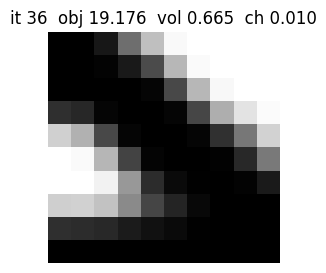

it.: 10 , obj.: 19.489 Vol.: 0.665, ch.: 0.110
it.: 20 , obj.: 19.218 Vol.: 0.665, ch.: 0.027
it.: 30 , obj.: 19.185 Vol.: 0.665, ch.: 0.020
Converged after 36 iterations


In [5]:
# ---------------- Optimization loop ----------------
x = volfrac*np.ones(nely*nelx)
xold = x.copy()
xPhys = x.copy()
g = 0.0
change, loop = 1.0, 0
history = []

fig, ax = plt.subplots(figsize=(8, 3))
im = ax.imshow(-xPhys.reshape((nelx, nely)).T, cmap='gray', interpolation='none',
               norm=colors.Normalize(vmin=-1, vmax=0))
ax.axis('off')
handle = display(fig, display_id=True)

while change > tol and loop < max_iter:
    loop += 1
    obj, ce = fe_compliance(xPhys, penal)
    dc = (-penal*xPhys**(penal-1)*(Emax-Emin))*ce
    dv = np.ones(nely*nelx)

    if ft == 0:
        dc = np.asarray(H @ (x*dc)).ravel()/Hs/np.maximum(0.001, x)
    else:
        dc = np.asarray(H @ (dc/Hs)).ravel()
        dv = np.asarray(H @ (dv/Hs)).ravel()

    xold[:] = x
    x[:], g = oc(nelx, nely, x, volfrac, dc, dv, g)
    xPhys[:] = x if ft == 0 else np.asarray(H @ x).ravel()/Hs

    change = np.linalg.norm(x - xold, np.inf)
    vol = (g + volfrac*nelx*nely)/(nelx*nely)
    history.append((loop, obj, vol, change))

    if loop % plot_every == 0 or change <= tol:
        im.set_array(-xPhys.reshape((nelx, nely)).T)
        ax.set_title(f"it {loop}  obj {obj:.3f}  vol {vol:.3f}  ch {change:.3f}")
        handle.update(fig)
    if loop % 10 == 0:
        print(f"it.: {loop} , obj.: {obj:.3f} Vol.: {vol:.3f}, ch.: {change:.3f}")

plt.close(fig)
print(f"Converged after {loop} iterations")

Threshold: 0.5
Compliance (continuous design, last iteration): 19.1748
Compliance (thresholded design)               : 17.3992
Volume fraction target                        : 0.6650
Actual volume fraction (thresholded, mean rho): 0.6800
Solid-element fraction (rho = 1)              : 0.6800


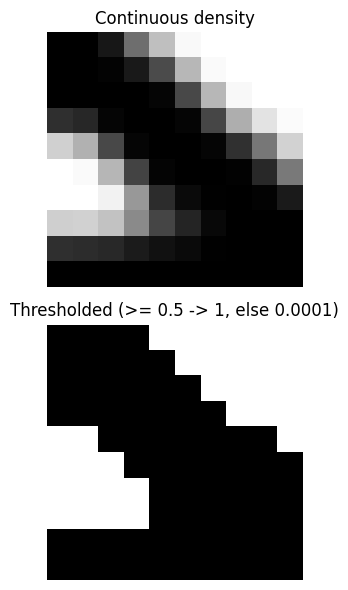

In [6]:
# ---------------- Thresholded final result ----------------
x_final = np.where(xPhys >= threshold, 1.0, void_density)

# Re-analyse the thresholded design with the same SIMP law used in the optimization
compliance_final, _ = fe_compliance(x_final, penal)
compliance_gray, _ = fe_compliance(xPhys, penal)

n_el = nelx*nely
solid_fraction = np.count_nonzero(x_final == 1.0)/n_el    # fraction of elements set to 1
actual_volume  = x_final.sum()/n_el                         # sum of densities / total (incl. 1e-4 voids)

print(f"Threshold: {threshold}")
print(f"Compliance (continuous design, last iteration): {compliance_gray:.4f}")
print(f"Compliance (thresholded design)               : {compliance_final:.4f}")
print(f"Volume fraction target                        : {volfrac:.4f}")
print(f"Actual volume fraction (thresholded, mean rho): {actual_volume:.4f}")
print(f"Solid-element fraction (rho = 1)              : {solid_fraction:.4f}")

fig, axs = plt.subplots(2, 1, figsize=(8, 6))
axs[0].imshow(-xPhys.reshape((nelx, nely)).T, cmap='gray', norm=colors.Normalize(vmin=-1, vmax=0))
axs[0].set_title("Continuous density"); axs[0].axis('off')
axs[1].imshow(-x_final.reshape((nelx, nely)).T, cmap='gray', norm=colors.Normalize(vmin=-1, vmax=0))
axs[1].set_title(f"Thresholded (>= {threshold} -> 1, else {void_density:g})"); axs[1].axis('off')
plt.tight_layout(); plt.show()